# Home-Care Pressure-to-Alpha — U.S. Healthcare Services
### Executable retrospective macro-factor falsification · 26 October 2026

**Not verified PIT. Not equity alpha.** This notebook is a self-contained computational narrative; the frozen data and research code are shipped with it. The benchmark is the 36-cell K-Food v3 study: explicit hypotheses, independently defined outcomes, source hierarchy, lead testing, falsification, exposure sensitivity, bias audit and a candid verdict.

## 01. Abstract

Does two-month-lagged home-health employment growth relative to hospital employment growth improve six-month-ahead nursing/residential-care YoY employment predictions? The empirical test below compares identical purged OOS origins, multiple baselines and uncertainty checks. **All historical observations are latest-revised CES snapshots, not contemporaneous first releases.**

In [1]:
from pathlib import Path
import json, hashlib, numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display, Markdown
from run_analysis import load_data, make_panel, walk_forward, score, run, moving_block_bootstrap
get_ipython().run_line_magic('matplotlib','inline')
ROOT=Path.cwd(); plt.rcParams.update({'figure.dpi':65,'axes.grid':True,'grid.alpha':.2})
raw=load_data(); panel=make_panel(raw)
print('Frozen observations:',len(raw),'panel observations:',len(panel),'as-of: 2026-10-26')

Frozen observations: 201 panel observations: 181 as-of: 2026-10-26


### Research status

The primary signal is **not** a trading signal; an industrial labor series is a proxy for labor demand, not company profits or stock total returns. The hypothesis can fail even when home care is a growing business because substitution, reimbursement and workforce supply affect employment differently.

## 02. Research Design & Hypotheses

**H1:** relative home-health expansion leads residential/nursing labor demand. **H2:** the factor improves forecasts beyond nursing persistence and hospital/national payroll controls. **H3:** any improvement survives horizons, release buffers, regime splits and block-aware falsification. **Null:** no incremental predictive information. **Counterthesis:** substitution away from institutions, staffing shortages, Medicaid/Medicare reimbursement and revision artifacts break the link.

In [2]:
design=pd.DataFrame({'test':['H1 transmission','H2 OOS incremental','H3 robustness','Null / failure'], 'criterion':['Economic mechanism; not assumed causal','Full RMSE < mean AND persistence AND macro','No collapse in regime/horizon/block placebo','Any failure -> no validated predictive alpha']})
display(design)

,test,criterion
0,H1 transmission,Economic mechanism; not assumed causal
1,H2 OOS incremental,Full RMSE < mean AND persistence AND macro
2,H3 robustness,No collapse in regime/horizon/block placebo
3,Null / failure,Any failure -> no validated predictive alpha


## 03. Industry Context

Care-setting segments are distinct: home health (NAICS 6216), hospitals (622), nursing/residential care (623). Changes in the mix of care delivery can represent substitution rather than additional systemwide demand. Employment is not patient utilization, reimbursements, sales or EPS.

In [3]:
display(raw.iloc[[0,-1]].T.rename(columns={raw.index[0]:'2010-01 (thousands)',raw.index[-1]:'2026-09 (thousands)'}).round(1))
print('Home health employment growth, 2010 to 2026:',round((raw.home.iloc[-1]/raw.home.iloc[0]-1)*100,2),'%')

date,2010-01 (thousands),2026-09 (thousands)
home,1059.9,1894.2
hospital,4671.6,5797.8
nursing,3100.7,3489.4
ambulatory,5905.4,9266.4
payroll,129802.0,159044.0


Home health employment growth, 2010 to 2026: 78.71 %


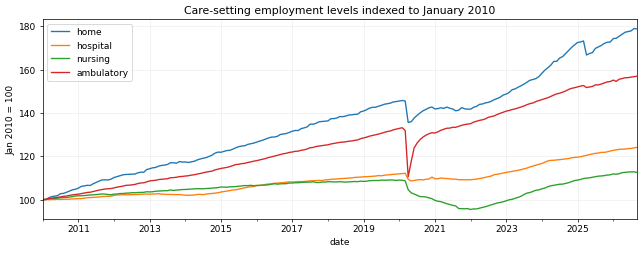

In [4]:
fig,ax=plt.subplots(figsize=(10,4))
(raw[['home','hospital','nursing','ambulatory']]/raw[['home','hospital','nursing','ambulatory']].iloc[0]*100).plot(ax=ax)
ax.set_title('Care-setting employment levels indexed to January 2010');ax.set_ylabel('Jan 2010 = 100');plt.tight_layout();plt.show()

### Mechanism vs measurement

A rising home-health workforce could signal patient preference, new insurance coverage, aging or provider entry; none automatically implies increased nursing-facility demand. The observed April 2025 home-care drop should be investigated for classification or benchmarking before it is given a causal narrative.

## 04. Data & Source Integrity

Five BLS Current Employment Statistics series were retrieved through official FRED graph CSV endpoints and frozen to a common 2010-01–2026-09 monthly window. A/B/C provenance grades: all five are **A** for publisher quality, but their historical *revised* values are **not** archival first-release vintages. See the source register for exact URLs and `UNKNOWN` historical timestamps.

In [5]:
sources=pd.read_csv('data/source_register.csv');display(sources[['series_id','name','grade','historical_release_date','vintage_status']]);print('Source SHA256:',hashlib.sha256(Path('data/fred_ces_2010_2026_snapshot.csv').read_bytes()).hexdigest())

,series_id,name,grade,historical_release_date,vintage_status
0,CES6562160001,Home health care services,A,UNKNOWN for historical observations,2026-10-26 latest-revised snapshot; not histor...
1,CES6562200001,Hospitals,A,UNKNOWN for historical observations,2026-10-26 latest-revised snapshot; not histor...
2,CES6562300001,Nursing and residential care facilities,A,UNKNOWN for historical observations,2026-10-26 latest-revised snapshot; not histor...
3,CES6562100001,Ambulatory health care services,A,UNKNOWN for historical observations,2026-10-26 latest-revised snapshot; not histor...
4,PAYEMS,Total nonfarm payrolls,A,UNKNOWN for historical observations,2026-10-26 latest-revised snapshot; not histor...


Source SHA256: f1d5a8ff28a55f2d1798cbdb9cac239d46db6c006b0a9e1801abae1b3b1665f6


In [6]:
assert raw.notna().all().all() and (raw>0).all().all()
assert len(raw)==201 and raw.index.to_period('M').is_unique
print('QA PASS: complete monthly grid, no missing/nonpositive values; end-of-sample cross-check passed.')

QA PASS: complete monthly grid, no missing/nonpositive values; end-of-sample cross-check passed.


## 05. Point-in-Time Availability

At formation month `t`, predictors refer to `t−2` (two-month assumed buffer). Training rows `u` must satisfy `u+6+1 ≤ t` because the outcome at `u+6` needs a further month to be published. **These lags do not eliminate later benchmark revisions**: the experiment is a retrospective lead-association falsification, not an executable PIT backtest.

In [7]:
oos_check=walk_forward(panel)
print('OOS origins:',len(oos_check),'first:',oos_check.index.min().date(),'last:',oos_check.index.max().date())
print('Training rows min/max:',oos_check.train_n.min(),oos_check.train_n.max())
assert oos_check.train_n.min()>=60

OOS origins: 99 first: 2018-01-01 last: 2026-03-01
Training rows min/max: 76 174


## 06. Factor Construction

Let `g_X(t)=100 ln[X(t−2)/X(t−14)]`. Define the fixed, bounded factor `F(t)=tanh((g_home(t)−g_hospital(t))/5)`; 5 pp is an **ex-ante** saturation constant. The target is `Y(t)=100 ln[N(t+6)/N(t−6)]`, i.e. the nursing/residential YoY log-growth rate measured six months after formation. Controls are lagged nursing, national payroll and hospital YoY growth; ridge α=10 with train-only scaling.

In [8]:
display(panel[['home_yoy','hospital_yoy','nursing_yoy','payroll_yoy','factor','target']].iloc[[0,24,48,-1]].round(3))
assert np.all(np.abs(panel.factor)<=1)

,home_yoy,hospital_yoy,nursing_yoy,payroll_yoy,factor,target
formation_date,,,,,,
2011-03-01,5.140,0.463,1.723,0.794,0.733,1.562
2013-03-01,3.607,0.526,0.961,1.498,0.549,0.926
2015-03-01,3.731,1.448,1.112,2.162,0.427,1.246
2026-03-01,1.045,2.608,2.555,0.205,-0.303,1.455


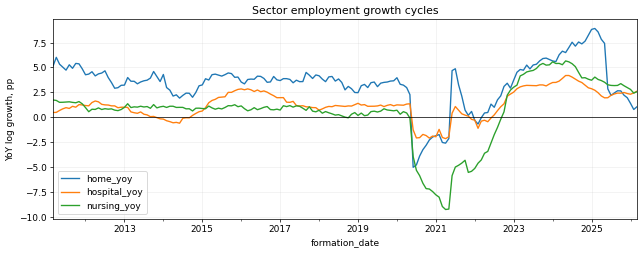

In [9]:
fig,ax=plt.subplots(figsize=(10,4));panel[['home_yoy','hospital_yoy','nursing_yoy']].plot(ax=ax)
ax.axhline(0,color='black',lw=.8);ax.set_ylabel('YoY log growth, pp');ax.set_title('Sector employment growth cycles');plt.tight_layout();plt.show()

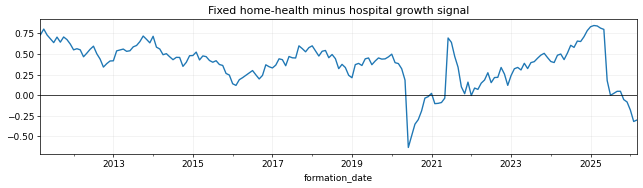

In [10]:
fig,ax=plt.subplots(figsize=(10,3));panel.factor.plot(ax=ax)
ax.axhline(0,color='black',lw=.8);ax.set_title('Fixed home-health minus hospital growth signal');plt.tight_layout();plt.show()

## 07. Exposure & Transmission

This is a **NAICS segment exposure** hypothesis, not a portfolio of listed companies. Home health is the positive factor leg, hospitals the negative leg, nursing/residential care the outcome, and broad ambulatory care an overlapping alternative proxy. A 1,000-scenario mix varies home weight 0.5–1.0 against ambulatory weight 0.5–0.0; these are analyst sensitivity weights, **not** historical firm revenue shares.

In [11]:
exposure_map=pd.read_csv('data/exposure_map.csv');display(exposure_map[['segment','naics','role','scenario_weight','company_level_mapping']])

,segment,naics,role,scenario_weight,company_level_mapping
0,Home health care services,6216,candidate growth signal,1.0 base; 0.5-1.0 stress,NOT AVAILABLE
1,Hospitals,622,subtract sector growth and macro control,-1.0,NOT AVAILABLE
2,Ambulatory care services,621,alternative proxy (includes home health),0.0 base; 0.0-0.5 stress,NOT AVAILABLE
3,Nursing and residential care,623,independent sector outcome,0.0,NOT AVAILABLE


### No issuer-level inference

Company-specific fundamental exposure weights, historical securities universes, dividend-adjusted returns and delisting histories are **not available in this study**. Accordingly company leave-one-out, equity rank IC, long-short return and Sharpe are **not applicable**, rather than treated as tests passed.

## 08. Outcomes & Baselines

Primary outcome: future nursing/residential-care **employment growth**, not returns. Every model forecasts the **same OOS months** with an expanding training window and matured-label purge. Baselines: historical mean, nursing persistence, nursing+hospital+national-payroll ridge, full factor-augmented ridge, factor-only and ablations. Evaluation uses RMSE/MAE in percentage points; no post-hoc parameter tuning.

In [12]:
models=['mean','persistence','macro','full','factor_only','home_only','alt_ambulatory','no_payroll','no_hospital']
print('Models:',', '.join(models));print('Ridge alpha: 10; initial OOS: 2018-01; label purge: 7 months')

Models: mean, persistence, macro, full, factor_only, home_only, alt_ambulatory, no_payroll, no_hospital
Ridge alpha: 10; initial OOS: 2018-01; label purge: 7 months


## 09. Empirical Findings

The next cell recomputes the **full 1,000 block-shuffle refits, 1,000 exposure perturbations and 2,000 block-bootstrap draws** from frozen inputs. It does not fetch live data, and the numerical outputs are independently checked against committed `results/metrics.json`.

In [13]:
metrics,raw2,panel2,oos,placebo,exposure=run(draws=1000,bootstrap=2000,write=False)
published=json.loads(Path('results/metrics.json').read_text())
assert np.isclose(metrics['scorecard']['full']['rmse'],published['scorecard']['full']['rmse'])
assert len(oos)==99
print('Recomputed all primary OOS and 1000/1000/2000 sensitivity draws; numerical snapshot matches.')

Recomputed all primary OOS and 1000/1000/2000 sensitivity draws; numerical snapshot matches.


In [14]:
scorecard=pd.DataFrame(metrics['scorecard']).T[['rmse','mae','n']]
display(scorecard.round(3));print('Macro minus full RMSE:',round(scorecard.loc['macro','rmse']-scorecard.loc['full','rmse'],3),'pp')

,rmse,mae,n
mean,4.349,3.534,99.0
persistence,3.760,2.551,99.0
macro,5.453,3.240,99.0
full,5.562,3.364,99.0
factor_only,4.454,3.579,99.0
home_only,5.578,3.287,99.0
alt_ambulatory,4.989,3.057,99.0
no_payroll,3.739,2.573,99.0
no_hospital,5.560,3.330,99.0


Macro minus full RMSE: -0.109 pp


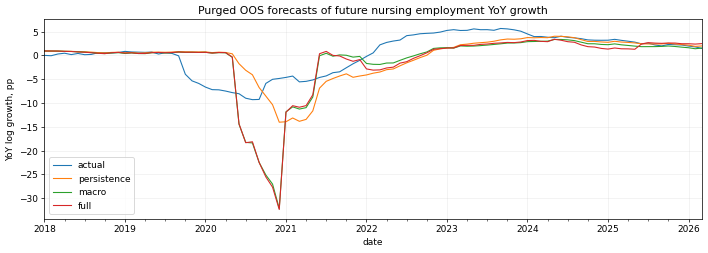

In [15]:
fig,ax=plt.subplots(figsize=(11,4));oos[['actual','persistence','macro','full']].plot(ax=ax,lw=1.2)
ax.set_title('Purged OOS forecasts of future nursing employment YoY growth');ax.set_ylabel('YoY log growth, pp');plt.tight_layout();plt.show()

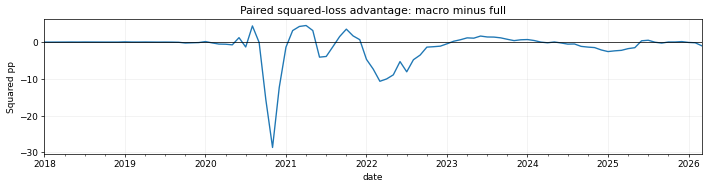

In [16]:
fig,ax=plt.subplots(figsize=(11,3));((oos.actual-oos.macro)**2-(oos.actual-oos.full)**2).plot(ax=ax)
ax.axhline(0,color='black',lw=.8);ax.set_title('Paired squared-loss advantage: macro minus full');ax.set_ylabel('Squared pp');plt.tight_layout();plt.show()

### Interpretation of negative predictive results

The candidate loses to **both** the macro-control model and the simpler nursing-persistence model. The macro baseline itself can be unstable during pandemic and labor-market breaks. The lower-complexity persistence comparison is essential; a slight improvement over a poor multivariate model would not suffice for a claim of useful alpha.

## 10. Robustness & Placebos

A 12-month block shuffle reassigns contiguous signal blocks and refits the full expanding-window model **1,000 times**. It is exploratory because nonstationary blocks are not exchangeable; its tail fraction is **not an exact p-value**. The paired 2,000-draw moving-block bootstrap addresses overlapping forecast errors descriptively, and 1,000 scenario exposure perturbations test sensitivity to the definition of the home-health leg.

In [17]:
print('Observed macro-minus-full RMSE:',round(metrics['block_placebo']['observed_improvement'],3),'pp')
print('Exploratory block-shuffle tail fraction:',round(metrics['block_placebo']['tail_fraction_exploratory'],3))
print('Bootstrap 95% CI:',np.round(metrics['bootstrap']['macro_minus_full_ci95'],3))
print('Exposure mixture median gain:',round(metrics['exposure_sensitivity']['median_delta_rmse'],3),'pp')

Observed macro-minus-full RMSE: -0.109 pp
Exploratory block-shuffle tail fraction: 0.73
Bootstrap 95% CI: [-0.268 -0.017]
Exposure mixture median gain: 0.025 pp


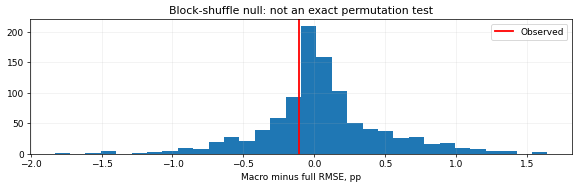

In [18]:
fig,ax=plt.subplots(figsize=(9,3));ax.hist(placebo['null'],bins=32)
ax.axvline(placebo['observed_improvement'],color='red',lw=2,label='Observed');ax.legend();ax.set_title('Block-shuffle null: not an exact permutation test');ax.set_xlabel('Macro minus full RMSE, pp');plt.tight_layout();plt.show()

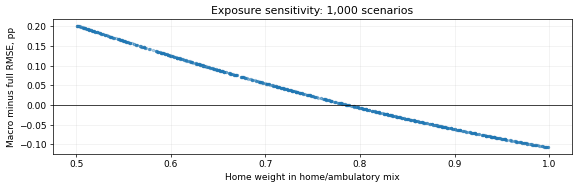

In [19]:
fig,ax=plt.subplots(figsize=(9,3));ax.scatter(exposure.home_weight,exposure.delta_rmse_macro_minus_full,s=7,alpha=.35)
ax.axhline(0,color='black',lw=.8);ax.set_xlabel('Home weight in home/ambulatory mix');ax.set_ylabel('Macro minus full RMSE, pp');ax.set_title('Exposure sensitivity: 1,000 scenarios');plt.tight_layout();plt.show()

## 11. Regime Sensitivity

Pre-2020, 2020+, exclusion of 2020–2021, alternative 3/9-month horizons, longer 3/4-month release buffers and an 84-month rolling training window test specification fragility. **They are exploratory, not independent pre-registered discoveries.** Overlapping YoY targets make naive iid significance tests invalid.

In [20]:
robust=pd.DataFrame(metrics['robustness']).T
robust['macro_minus_full']=robust.macro_rmse-robust.full_rmse
display(robust.round(3))

,n,macro_rmse,full_rmse,persistence_rmse,macro_minus_full
pre_2020,24.0,2.079,2.084,2.116,-0.005
2020_onward,75.0,6.154,6.281,4.150,-0.126
excluding_2020_2021,75.0,2.374,2.578,2.568,-0.204
horizon_3m,102.0,3.201,3.331,2.396,-0.130
horizon_9m,96.0,8.815,9.122,4.713,-0.307
lag_3m,99.0,6.471,6.623,4.005,-0.152
lag_4m,99.0,7.684,7.944,4.175,-0.259
rolling_84m,99.0,6.663,6.558,3.965,0.105


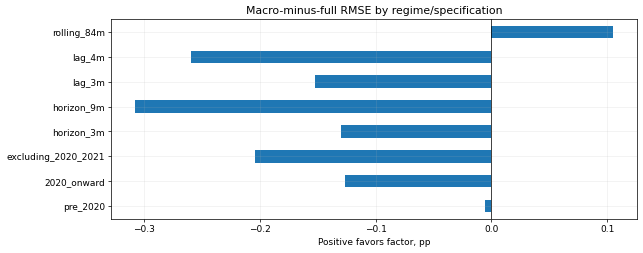

In [21]:
fig,ax=plt.subplots(figsize=(10,4));robust.macro_minus_full.plot.barh(ax=ax)
ax.axvline(0,color='black',lw=.8);ax.set_title('Macro-minus-full RMSE by regime/specification');ax.set_xlabel('Positive favors factor, pp');plt.tight_layout();plt.show()

,excluded_year,n,macro_minus_full_rmse
0,2018,87,-0.116
1,2019,87,-0.117
2,2020,87,-0.129
3,2021,87,-0.133
4,2022,87,-0.052
5,2023,87,-0.128
6,2024,87,-0.110
7,2025,87,-0.106
8,2026,96,-0.109


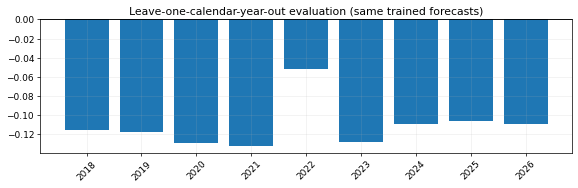

In [22]:
leave=pd.DataFrame(metrics['leave_one_year_out'])
display(leave.round(3))
fig,ax=plt.subplots(figsize=(9,3));ax.bar(leave.excluded_year.astype(str),leave.macro_minus_full_rmse)
ax.axhline(0,color='black',lw=.8);ax.set_title('Leave-one-calendar-year-out evaluation (same trained forecasts)');ax.tick_params(axis='x',rotation=45);plt.tight_layout();plt.show()

## 12. Bias Audit & Verdict

**PIT leakage unresolved:** historical CES revisions are in the frozen 2026 snapshot. **Temporal dependence:** monthly origins share future 12-month YoY windows. **Selection/multiple testing:** the healthcare signal and additional variants were chosen after observing sector trends. **Exposure:** NAICS proxies are not company revenue weights. **No securities:** no firm filings, total returns, transaction costs, capacity or investable strategy. **Verdict: negative reproducible retrospective macro factor; not point-in-time and not equity alpha.**

In [23]:
bias=pd.DataFrame({'risk':['Publication/vintage','Overlapping outcomes','Multiple comparisons','Company exposure','Investability'], 'status':['UNKNOWN historical first-release vintages','12-month overlapping targets','Unadjusted exploratory variants','No dated firm-level shares','No returns, costs or universe']})
display(bias)
assert metrics['PIT_verified'] is False and metrics['equity_alpha_established'] is False

,risk,status
0,Publication/vintage,UNKNOWN historical first-release vintages
1,Overlapping outcomes,12-month overlapping targets
2,Multiple comparisons,Unadjusted exploratory variants
3,Company exposure,No dated firm-level shares
4,Investability,"No returns, costs or universe"


## 13. Reproduction

Offline reproduction from a clean checkout: `pip install -r requirements.txt`, `OPENBLAS_NUM_THREADS=1 python run_analysis.py`, `PYTHONPATH=. pytest -q tests`, and `jupyter nbconvert --to notebook --execute research.ipynb --output /tmp/healthcare-reexecuted.ipynb`. At repository root, `python scripts/validate_studies.py` checks the canonical 15-section structure. The notebook itself recomputes results and persists executed tables and figures.

In [24]:
print('Source SHA256:',metrics['source_sha256']);print('Reproduction files:',len(list(Path('results').glob('*'))),'result files and',len(list(Path('figures').glob('*.png'))),'diagnostic figures')
assert metrics['source_sha256']==hashlib.sha256(Path('data/fred_ces_2010_2026_snapshot.csv').read_bytes()).hexdigest()

Source SHA256: f1d5a8ff28a55f2d1798cbdb9cac239d46db6c006b0a9e1801abae1b3b1665f6
Reproduction files: 10 result files and 8 diagnostic figures


## 14. Next-Stage Protocol

1. Archive observation-by-observation ALFRED/BLS first-release CES vintages and actual publication timestamps. 2. Audit the April 2025 home-health employment break. 3. Collect independent CMS home-care utilization, hospital discharge and nursing occupancy data with vintage/reimbursement dates. 4. Only after PIT fundamentals are validated, map historical issuer exposures and test security total returns with delistings, benchmarks and costs. 5. Preregister one factor family and reserve a clean forward holdout to address repeated research selection.

In [25]:
next_stage=pd.DataFrame({'stage':['PIT reconstruction','Independent utilization outcome','Firm fundamentals','Equity total returns'], 'gate':['Original release vintage and timestamps','Claims/occupancy with release lags','Dated segment disclosures','Historical universe, costs and holdout']})
display(next_stage)

,stage,gate
0,PIT reconstruction,Original release vintage and timestamps
1,Independent utilization outcome,Claims/occupancy with release lags
2,Firm fundamentals,Dated segment disclosures
3,Equity total returns,"Historical universe, costs and holdout"


## 15. Sources & Artifacts

Original publishers: U.S. Bureau of Labor Statistics, accessed through Federal Reserve Bank of St. Louis FRED. Series: [home health](https://fred.stlouisfed.org/series/CES6562160001), [hospitals](https://fred.stlouisfed.org/series/CES6562200001), [nursing/residential](https://fred.stlouisfed.org/series/CES6562300001), [ambulatory](https://fred.stlouisfed.org/series/CES6562100001), [national payroll](https://fred.stlouisfed.org/series/PAYEMS). Data freeze 2026-10-26; latest source release 2026-10-02; **historical observation release dates UNKNOWN**. Full provenance in `data/source_register.csv`; frozen and derived inputs in `data/`, 8 computed PNG figures in `figures/`, all forecast/null/sensitivity results in `results/`, unit tests in `tests/`.

In [26]:
display(pd.read_csv('data/source_register.csv')[['series_id','original_series_url','latest_source_release']]);print('FINAL VERDICT: negative retrospective macro lead-factor test; no PIT or equity alpha.')

,series_id,original_series_url,latest_source_release
0,CES6562160001,https://fred.stlouisfed.org/series/CES6562160001,2026-10-02
1,CES6562200001,https://fred.stlouisfed.org/series/CES6562200001,2026-10-02
2,CES6562300001,https://fred.stlouisfed.org/series/CES6562300001,2026-10-02
3,CES6562100001,https://fred.stlouisfed.org/series/CES6562100001,2026-10-02
4,PAYEMS,https://fred.stlouisfed.org/series/PAYEMS,2026-10-02


FINAL VERDICT: negative retrospective macro lead-factor test; no PIT or equity alpha.
